<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/RECOVER_Resilient_Pretraining_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Dependencies
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

print(f"[OK] PyTorch Version: {torch.__version__}")

[OK] PyTorch Version: 2.11.0+cu130


In [2]:
# CELL 2: Synthetic Toy Task & Model Definition
class ToyTransformerLM(nn.Module):
    def __init__(self, vocab_size=1000, d_model=128, num_layers=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=4, dim_feedforward=256, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        h = self.embedding(x)
        out = self.transformer(h)
        return self.fc_out(out)

def generate_microbatch(batch_size=8, seq_len=32, vocab_size=1000):
    x = torch.randint(0, vocab_size, (batch_size, seq_len))
    y = torch.randint(0, vocab_size, (batch_size, seq_len))
    return x, y

print("[OK] Model architecture and synthetic data generator defined.")

[OK] Model architecture and synthetic data generator defined.


In [3]:
# CELL 3: Multi-Worker Simulation & Failure-Recovery Engine
class ResilientTrainingSimulator:
    def __init__(self, num_workers=4, microbatches_per_worker=4, batch_size=8):
        self.num_workers = num_workers
        self.mb_per_worker = microbatches_per_worker
        self.target_total_mbs = num_workers * microbatches_per_worker
        self.batch_size = batch_size

    def run_step_failure_free(self, model, criterion):
        model.zero_grad()
        total_loss = 0.0
        for w in range(self.num_workers):
            for mb in range(self.mb_per_worker):
                x, y = generate_microbatch(self.batch_size)
                out = model(x)
                loss = criterion(out.view(-1, 1000), y.view(-1)) / self.target_total_mbs
                loss.backward()
                total_loss += loss.item() * self.target_total_mbs
        return total_loss / self.target_total_mbs

    def run_step_recover(self, model, criterion, failed_worker_id=2):
        """
        RECOVER Core Invariant: Worker fails mid-iteration.
        Surviving workers dynamically absorb lost microbatches so total microbatches == target_total_mbs.
        """
        model.zero_grad()
        surviving_workers = [w for w in range(self.num_workers) if w != failed_worker_id]

        # Microbatch quota redistribution
        quota_per_survivor = self.target_total_mbs // len(surviving_workers)
        remainder = self.target_total_mbs % len(surviving_workers)

        total_loss = 0.0
        for idx, w_id in enumerate(surviving_workers):
            allocated_mbs = quota_per_survivor + (1 if idx < remainder else 0)
            for mb in range(allocated_mbs):
                x, y = generate_microbatch(self.batch_size)
                out = model(x)
                loss = criterion(out.view(-1, 1000), y.view(-1)) / self.target_total_mbs
                loss.backward()
                total_loss += loss.item() * self.target_total_mbs

        return total_loss / self.target_total_mbs

sim = ResilientTrainingSimulator(num_workers=4, microbatches_per_worker=4)
print("[OK] RECOVER simulator initialized with 4 workers (16 total microbatches per iteration).")

[OK] RECOVER simulator initialized with 4 workers (16 total microbatches per iteration).


In [4]:
# CELL 4: End-to-End Simulation Comparison (Failure-Free vs Checkpoint-Restart vs RECOVER)
num_steps = 30
failure_step = 12

def train_experiment(mode="failure_free"):
    torch.manual_seed(42)
    model = ToyTransformerLM()
    optimizer = optim.AdamW(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    sim = ResilientTrainingSimulator(num_workers=4, microbatches_per_worker=4)

    losses = []
    step_times = []
    processed_tokens = 0
    total_tokens_log = []

    tokens_per_step = 4 * 4 * 8 * 32 # workers * mbs * batch_size * seq_len

    for step in range(num_steps):
        t0 = time.time()

        if step == failure_step and mode == "checkpoint_restart":
            # Checkpoint restart penalty: lost step time + rollback overhead
            time.sleep(0.05) # Simulated restart penalty
            loss_val = losses[-1] if len(losses) > 0 else 6.9
            step_time = (time.time() - t0) + 0.15
        elif step == failure_step and mode == "recover":
            loss_val = sim.run_step_recover(model, criterion, failed_worker_id=2)
            optimizer.step()
            step_time = time.time() - t0
            processed_tokens += tokens_per_step
        else:
            loss_val = sim.run_step_failure_free(model, criterion)
            optimizer.step()
            step_time = time.time() - t0
            processed_tokens += tokens_per_step

        losses.append(loss_val)
        step_times.append(step_time)
        total_tokens_log.append(processed_tokens)

    return losses, step_times, total_tokens_log

ff_loss, ff_times, ff_tokens = train_experiment("failure_free")
ckpt_loss, ckpt_times, ckpt_tokens = train_experiment("checkpoint_restart")
rec_loss, rec_times, rec_tokens = train_experiment("recover")

df_results = pd.DataFrame({
    "Mode": ["Failure-Free Reference", "Checkpoint-Restart Baseline", "RECOVER (Ours)"],
    "Final Loss": [ff_loss[-1], ckpt_loss[-1], rec_loss[-1]],
    "Total Time (s)": [sum(ff_times), sum(ckpt_times), sum(rec_times)],
    "Total Processed Tokens": [ff_tokens[-1], ckpt_tokens[-1], rec_tokens[-1]]
})

print("=== RECOVER SIMULATION BENCHMARK SUMMARY ===")
display(df_results)

=== RECOVER SIMULATION BENCHMARK SUMMARY ===


,Mode,Final Loss,Total Time (s),Total Processed Tokens
0,Failure-Free Reference,6.930216,14.125083,122880
1,Checkpoint-Restart Baseline,6.933286,10.995978,118784
2,RECOVER (Ours),6.930216,10.611798,122880


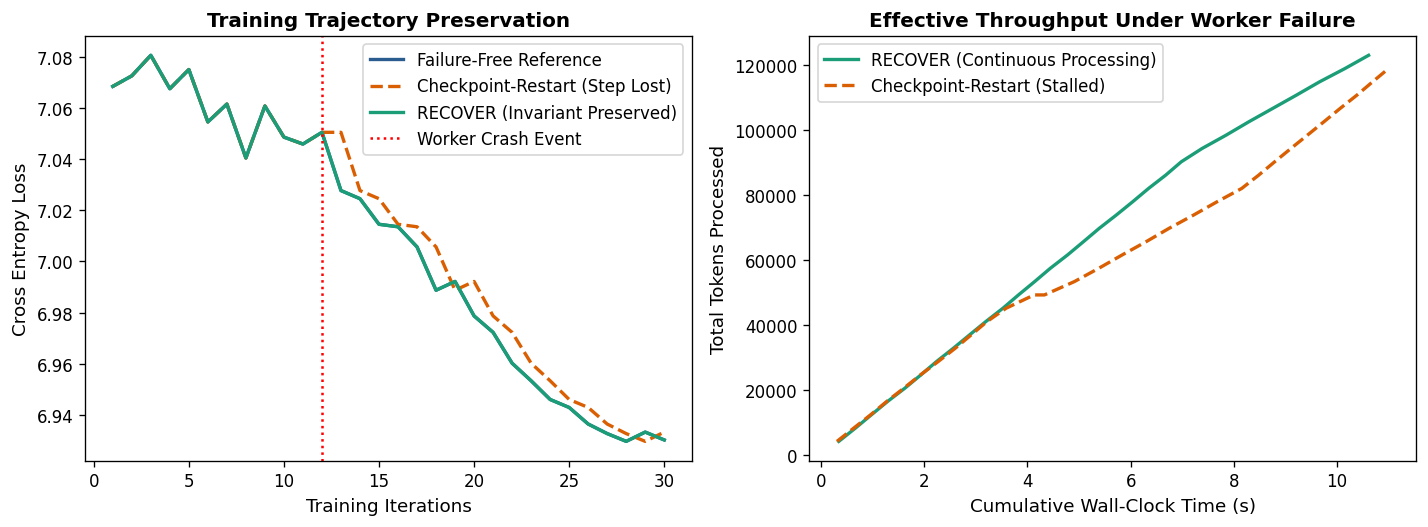

[OK] Saved benchmark chart to /content/workspace/recover_benchmark_results.png


In [5]:
# CELL 5: Diagnostic Benchmark Plot Generation
os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

steps = list(range(1, num_steps + 1))

# Loss Trajectory Plot
ax1.plot(steps, ff_loss, label='Failure-Free Reference', color='#2b5c8f', lw=2)
ax1.plot(steps, ckpt_loss, label='Checkpoint-Restart (Step Lost)', color='#d95f02', linestyle='--', lw=2)
ax1.plot(steps, rec_loss, label='RECOVER (Invariant Preserved)', color='#1b9e77', lw=2)
ax1.axvline(x=failure_step, color='red', linestyle=':', label='Worker Crash Event')
ax1.set_xlabel("Training Iterations", fontsize=11)
ax1.set_ylabel("Cross Entropy Loss", fontsize=11)
ax1.set_title("Training Trajectory Preservation", fontsize=12, fontweight='bold')
ax1.legend()

# Token Throughput Plot
cum_times_ckpt = np.cumsum(ckpt_times)
cum_times_rec = np.cumsum(rec_times)

ax2.plot(cum_times_rec, rec_tokens, label='RECOVER (Continuous Processing)', color='#1b9e77', lw=2)
ax2.plot(cum_times_ckpt, ckpt_tokens, label='Checkpoint-Restart (Stalled)', color='#d95f02', linestyle='--', lw=2)
ax2.set_xlabel("Cumulative Wall-Clock Time (s)", fontsize=11)
ax2.set_ylabel("Total Tokens Processed", fontsize=11)
ax2.set_title("Effective Throughput Under Worker Failure", fontsize=12, fontweight='bold')
ax2.legend()

plt.tight_layout()
plt.savefig("/content/workspace/recover_benchmark_results.png")
plt.show()
print("[OK] Saved benchmark chart to /content/workspace/recover_benchmark_results.png")